In [3]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

DATA_PATH = "public-health-statistics-infant-mortality-in-chicago-2005-2009.csv"
FIG_DIR = Path("reports/figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)

COLORS = {"Significantly higher": "#c0392b",
          "Significantly lower": "#2874a6",
          "Not distinguishable": "#7f8c8d"}
YEARS = [2005, 2006, 2007, 2008, 2009]

raw = pd.read_csv(DATA_PATH)
raw.columns = ["area_id", "area"] + [f"d{y}" for y in YEARS] + [
    "cum_deaths", "avg_deaths", "imr", "ci_low", "ci_high", "warning"]

# Row 0 is the citywide benchmark, not a community area
city = raw[raw["area_id"] == 0].iloc[0]
df = raw[raw["area_id"] != 0].copy()
CITY_IMR = city["imr"]

df["reliable"] = df["warning"].isna()
df["est_births"] = (df["cum_deaths"] / df["imr"] * 1000).round()  # derived denominator
df["status"] = np.select(
    [df["ci_low"] > CITY_IMR, df["ci_high"] < CITY_IMR],
    ["Significantly higher", "Significantly lower"],
    default="Not distinguishable")
df.head()

,area_id,area,d2005,d2006,d2007,d2008,d2009,cum_deaths,avg_deaths,imr,ci_low,ci_high,warning,reliable,est_births,status
0,1,Rogers Park,7,8,7,2,5,29,6,6.4,4.3,9.2,NaN,True,4531.0,Not distinguishable
1,2,West Ridge,9,5,8,4,5,31,6,5.1,3.5,7.2,NaN,True,6078.0,Significantly lower
2,3,Uptown,2,7,4,7,5,25,5,6.5,4.2,9.6,NaN,True,3846.0,Not distinguishable
3,4,Lincoln Square,2,2,3,3,2,12,2,3.8,2.0,6.6,Rate and confidence interval estimates are unr...,False,3158.0,Significantly lower
4,5,North Center,1,1,3,2,2,9,2,2.7,1.2,5.1,Rate and confidence interval estimates are unr...,False,3333.0,Significantly lower


In [5]:
sig_high = df[df["status"] == "Significantly higher"]
sig_low = df[df["status"] == "Significantly lower"]

print(f"Community areas:            {len(df)}")
print(f"Citywide IMR (2005-2009):   {CITY_IMR} per 1,000 live births")
print(f"Areas above citywide rate:  {(df['imr'] > CITY_IMR).sum()}")
print(f"Unreliable estimates:       {(~df['reliable']).sum()} of {len(df)}")
print(f"Significantly higher:       {len(sig_high)} areas, "
      f"{sig_high['cum_deaths'].sum() / df['cum_deaths'].sum():.1%} of deaths")
print(f"Significantly lower:        {len(sig_low)} areas")
print(f"Citywide deaths 2005 -> 2009: {int(city['d2005'])} -> {int(city['d2009'])} "
      f"({city['d2009'] / city['d2005'] - 1:+.1%})")

Community areas:            77
Citywide IMR (2005-2009):   8.1 per 1,000 live births
Areas above citywide rate:  38
Unreliable estimates:       38 of 77
Significantly higher:       12 areas, 35.6% of deaths
Significantly lower:        15 areas
Citywide deaths 2005 -> 2009: 387 -> 355 (-8.3%)


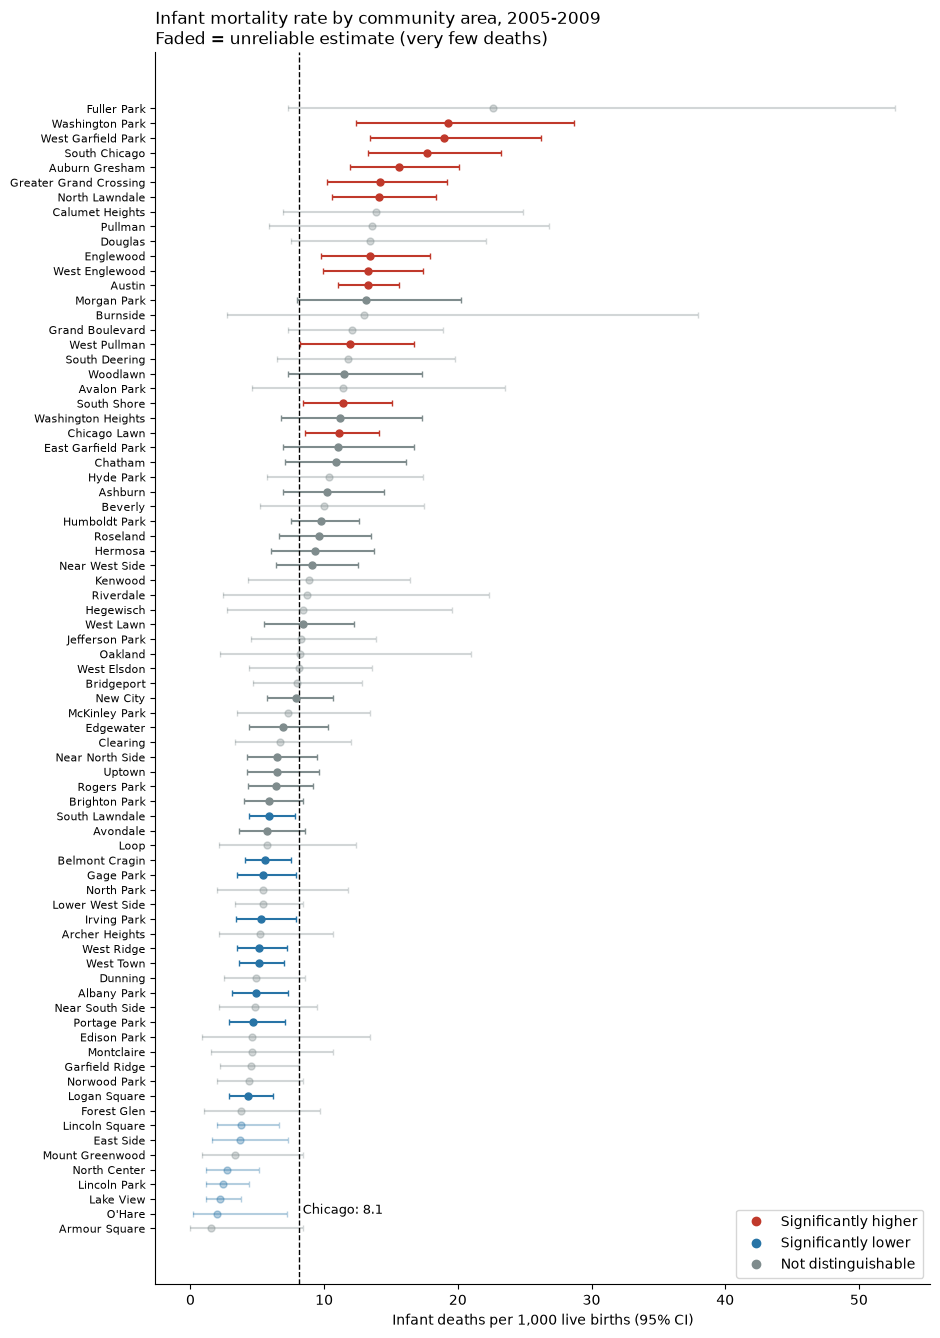

In [6]:
d = df.sort_values("imr").reset_index(drop=True)
fig, ax = plt.subplots(figsize=(10, 16))
for i, r in d.iterrows():
    ax.errorbar(r["imr"], i,
                xerr=[[r["imr"] - r["ci_low"]], [r["ci_high"] - r["imr"]]],
                fmt="o", color=COLORS[r["status"]], ecolor=COLORS[r["status"]],
                alpha=1.0 if r["reliable"] else 0.35, capsize=2, ms=5)
ax.axvline(CITY_IMR, color="black", ls="--", lw=1)
ax.text(CITY_IMR + 0.3, 1, f"Chicago: {CITY_IMR}", fontsize=9)
ax.set_yticks(range(len(d)))
ax.set_yticklabels(d["area"], fontsize=8)
ax.set_xlabel("Infant deaths per 1,000 live births (95% CI)")
ax.set_title("Infant mortality rate by community area, 2005-2009\n"
             "Faded = unreliable estimate (very few deaths)", loc="left")
for label, c in COLORS.items():
    ax.plot([], [], "o", color=c, label=label)
ax.legend(loc="lower right")
sns.despine()
fig.savefig(FIG_DIR / "01_ranked_rates_with_ci.png", dpi=200, bbox_inches="tight")

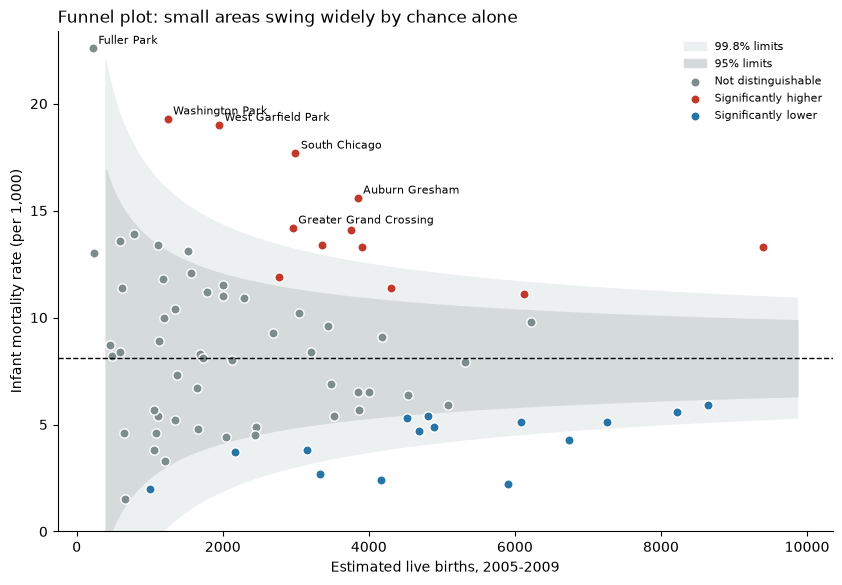

In [7]:
p = CITY_IMR / 1000
n = np.linspace(400, df["est_births"].max() * 1.05, 300)
se = 1000 * np.sqrt(p / n)   # normal approximation to Poisson noise

fig, ax = plt.subplots(figsize=(10, 6.5))
ax.fill_between(n, CITY_IMR - 3.09 * se, CITY_IMR + 3.09 * se, color="#ecf0f1", label="99.8% limits")
ax.fill_between(n, CITY_IMR - 1.96 * se, CITY_IMR + 1.96 * se, color="#d5dbdb", label="95% limits")
ax.axhline(CITY_IMR, color="black", ls="--", lw=1)
ax.set_ylim(bottom=0)
for status, g in df.groupby("status"):
    ax.scatter(g["est_births"], g["imr"], s=45, color=COLORS[status], label=status, edgecolor="white")
for _, r in df.nlargest(6, "imr").iterrows():
    ax.annotate(r["area"], (r["est_births"], r["imr"]), fontsize=8,
                xytext=(4, 3), textcoords="offset points")
ax.set_xlabel("Estimated live births, 2005-2009")
ax.set_ylabel("Infant mortality rate (per 1,000)")
ax.set_title("Funnel plot: small areas swing widely by chance alone", loc="left")
ax.legend(frameon=False, fontsize=8)
sns.despine()
fig.savefig(FIG_DIR / "02_funnel_plot.png", dpi=200, bbox_inches="tight")